# Aprendizaje de Máquina: Proyecto

Arantxa Valencia Reyes - 0265784

Ana Luisa Villeda Anleu - 0266043

## Clasificación del Estado de Madurez del Aguacate

El objetivo del proyecto es desarrollar y evaluar un sistema de clasificación multiclase mediante algoritmos de Machine Learning para determinar con precisión el estado de madurez del aguacate (ripe, hard, pre-conditioned, breaking) a partir de sus propiedades físicas, acústicas y colorimétricas, identificando el modelo predictivo óptimo para su aplicación en el control de calidad automatizado.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score,
                              roc_curve, roc_auc_score, precision_recall_curve, RocCurveDisplay)
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid", context="notebook")
UP_BLUE, UP_RED, UP_GOLD = "#003366", "#BA0C2F", "#C69214"

# Importación del Dataset

In [2]:
df = pd.read_csv("./avocado_ripeness_dataset.csv")
df.columns = ["firmness", "hue", "saturation", "brightness", "color_category", "sound_db", "weight_g", "size_cm3", "ripeness"]

print(df.shape)
df.head()

(250, 9)


,firmness,hue,saturation,brightness,color_category,sound_db,weight_g,size_cm3,ripeness
0,14.5,19,40,26,black,34,175,261,ripe
1,71.7,53,69,75,green,69,206,185,pre-conditioned
2,88.5,60,94,46,dark green,79,220,143,hard
3,93.8,105,87,41,dark green,75,299,140,hard
4,42.5,303,58,32,purple,63,200,227,breaking


Variable objetivo: ripeness

# Análisis Exploratorio

Primero evaluamos la información general del dataset, los tipos de variables, si había valores nulos o filas duplicadas. Encontramos que el dataset estaba prácticamente limpio.

In [3]:
print(df.info())
print(f"\nValores nulos por columna:\n{df.isnull().sum()}")
print(f"\nFilas duplicadas: {df.duplicated().sum()}")

display(df.describe().T[['mean', 'std', 'min', '50%', 'max']])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   firmness        250 non-null    float64
 1   hue             250 non-null    int64  
 2   saturation      250 non-null    int64  
 3   brightness      250 non-null    int64  
 4   color_category  250 non-null    object 
 5   sound_db        250 non-null    int64  
 6   weight_g        250 non-null    int64  
 7   size_cm3        250 non-null    int64  
 8   ripeness        250 non-null    object 
dtypes: float64(1), int64(6), object(2)
memory usage: 17.7+ KB
None

Valores nulos por columna:
firmness          0
hue               0
saturation        0
brightness        0
color_category    0
sound_db          0
weight_g          0
size_cm3          0
ripeness          0
dtype: int64

Filas duplicadas: 0


,mean,std,min,50%,max
firmness,50.6184,27.277678,10.3,48.95,98.8
hue,125.9440,117.137670,1.0,77.00,329.0
saturation,64.3560,17.377144,30.0,65.00,99.0
brightness,45.0720,19.116290,10.0,46.00,78.0
sound_db,58.0160,13.838126,30.0,60.00,79.0
weight_g,220.1880,34.405225,152.0,220.00,299.0
size_cm3,208.6440,55.940564,100.0,218.00,299.0


Procedimos con la evaluación de distribución de la variable objetivo, la cual también encontramos que estaba perfectamente balanceada entre las 5 categorías

/var/folders/0_/_kf7qc8s0k78kymk392z49100000gn/T/ipykernel_99105/3629208185.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x="ripeness", palette=[UP_BLUE], order=df["ripeness"].value_counts().index)
/var/folders/0_/_kf7qc8s0k78kymk392z49100000gn/T/ipykernel_99105/3629208185.py:2: UserWarning: 
The palette list has fewer values (1) than needed (5) and will cycle, which may produce an uninterpretable plot.
  ax = sns.countplot(data=df, x="ripeness", palette=[UP_BLUE], order=df["ripeness"].value_counts().index)


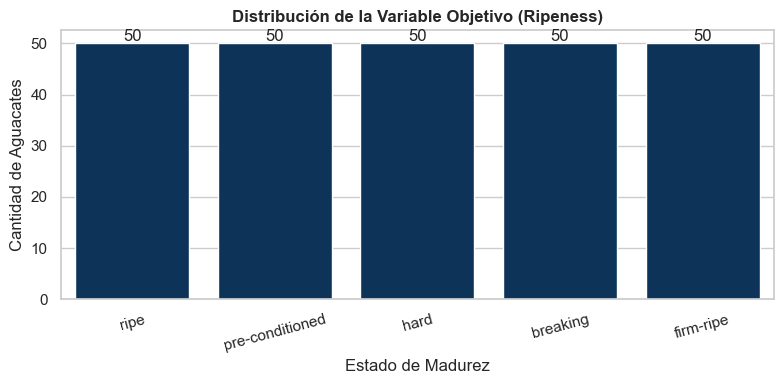

In [4]:
plt.figure(figsize=(8, 4))
ax = sns.countplot(data=df, x="ripeness", palette=[UP_BLUE], order=df["ripeness"].value_counts().index)
plt.title("Distribución de la Variable Objetivo (Ripeness)", fontsize=12, fontweight="bold")
plt.xlabel("Estado de Madurez")
plt.ylabel("Cantidad de Aguacates")
plt.xticks(rotation=15)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.show()

Procedimos a iterar sobre las variables numéricas del dataset para generar un histograma con estimación de densidad y un diagrama de caja por cada variable. Con esto pudimos analizar visualmente la forma de sus distribuciones, evaluar la necesidad de escalamiento e identificar la presencia de valores atípicos. Los hallazgos de esta exploración fueron los siguientes:

- Ausencia de Outliers: Ninguna de las 7 variables numéricas presenta valores atípicos (outliers) severos o aislados. Todos los datos se encuentran dentro de los límites esperados (los "bigotes" del diagrama de caja), por lo que no es necesario filtrar o eliminar observaciones.

- Distribución Bimodal en hue (Color): La variable del tono de color (hue) presenta dos picos pronunciados (aproximadamente entre 0–100 y 250–320). Esto indica la presencia natural de dos grupos bien diferenciados (por ejemplo, aguacates verdes frente a aguacates en tonos más oscuros/negros), siendo una variable altamente discriminatoria para determinar el estado de madurez.

- Escalas Heterogéneas entre Variables: Las variables manejan rangos de magnitudes muy distintos (por ejemplo, el peso weight_g va de 150 a 300 g, mientras que la firmeza firmness va de 10 a 100). Esto confirma la necesidad de estandarizar las variables (StandardScaler) antes de entrenar modelos basados en distancias (como KNN o LDA/QDA) para evitar que las variables con valores grandes dominen las predicciones.

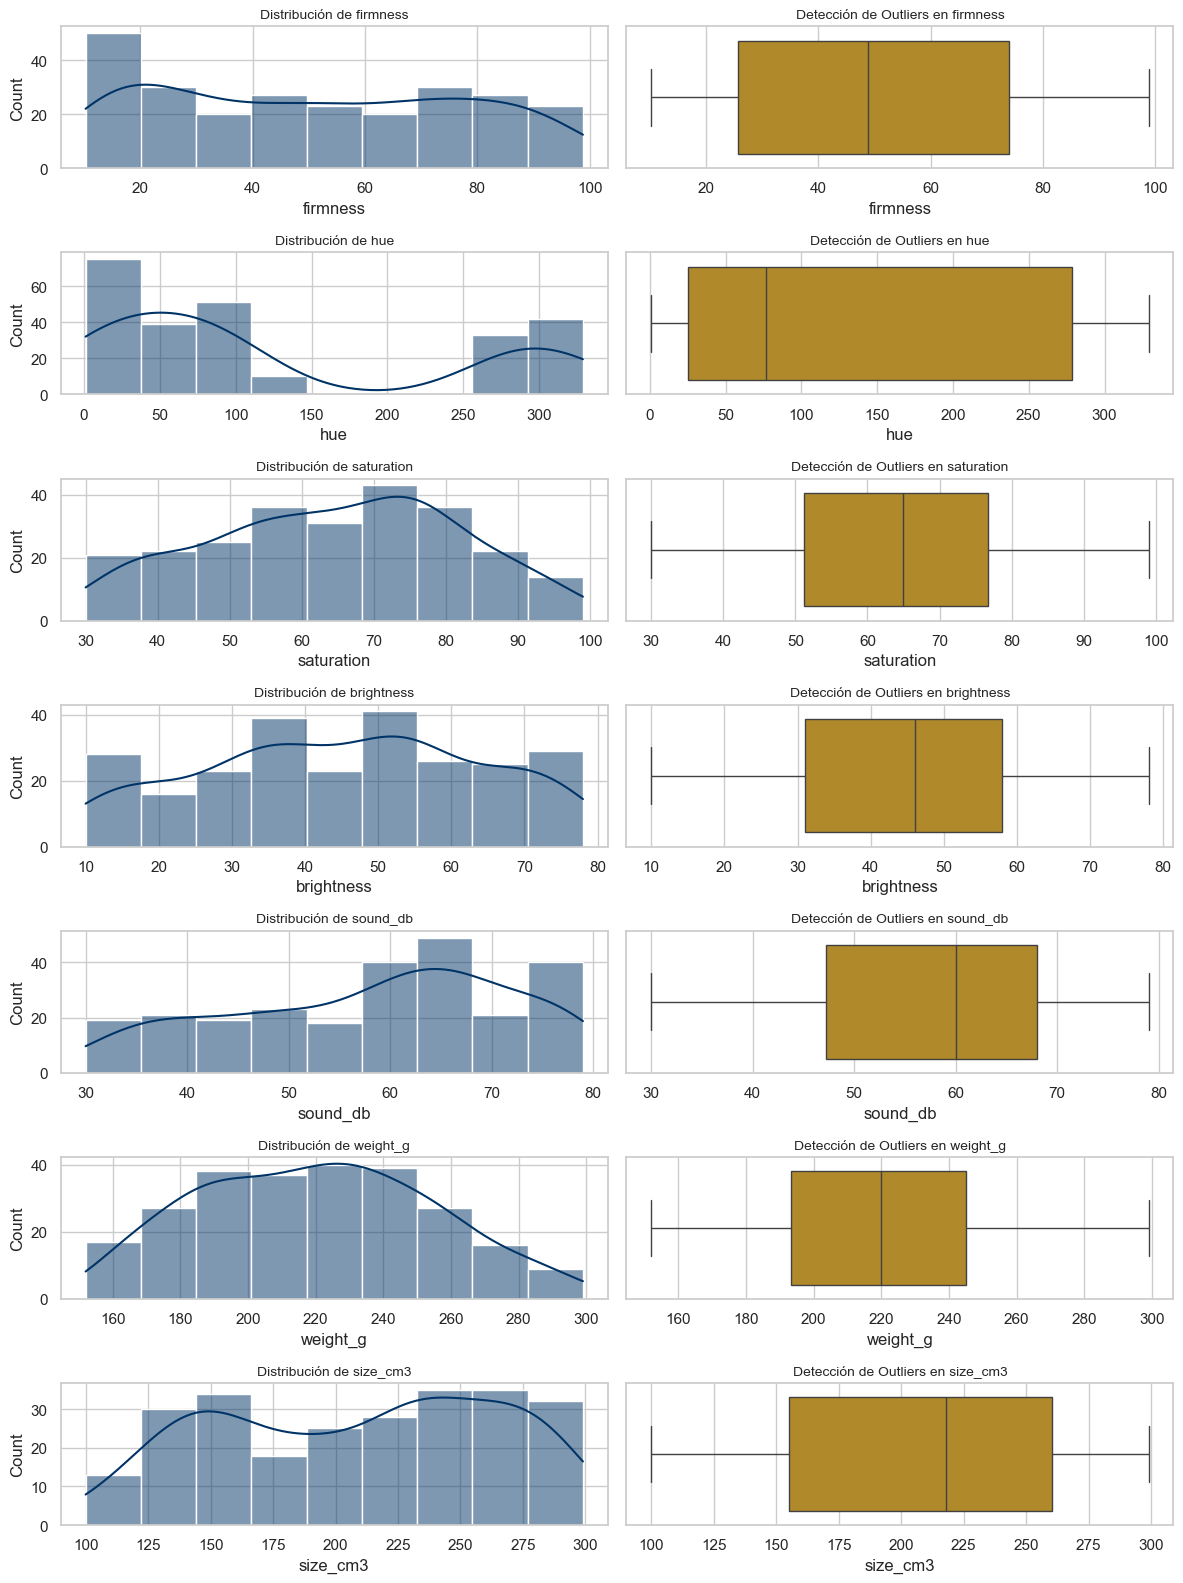

In [5]:
num_cols = ["firmness", "hue", "saturation", "brightness", "sound_db", "weight_g", "size_cm3"]

fig, axes = plt.subplots(len(num_cols), 2, figsize=(12, 16))
for i, col in enumerate(num_cols):
    # Histograma (Distribución)
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color="#003366")
    axes[i, 0].set_title(f"Distribución de {col}", fontsize=10)
    
    # Diagrama de caja (Outliers)
    sns.boxplot(x=df[col], ax=axes[i, 1], color="#C69214")
    axes[i, 1].set_title(f"Detección de Outliers en {col}", fontsize=10)

plt.tight_layout()
plt.show()

Matriz de correlación: El análisis reveló que variables como la firmeza, la acústica (sound_db), el tamaño y la saturación presentan una correlación lineal extremadamente alta con la madurez ($\vert{}r\vert{} > 0.70$), así como una severa multicolinealidad entre sí ($\vert{}r\vert{} > 0.90$). Por su parte, el tono de color (hue) mostró una correlación lineal nula ($r = -0.00$), pero una marcada distribución bimodal clave para la diferenciación de estados. Con base en estos hallazgos, decidimos aplicar un escalamiento estandarizado (StandardScaler) a todas las variables numéricas, conservar la variable hue por su valor no lineal y emplear reducción de dimensionalidad (PCA) en modelos lineales sensibles como LDA y QDA, mientras que para los modelos de árbol y ensamble (Random Forest y XGBoost) se mantendrán las variables originales al ser robustos ante la multicolinealidad.

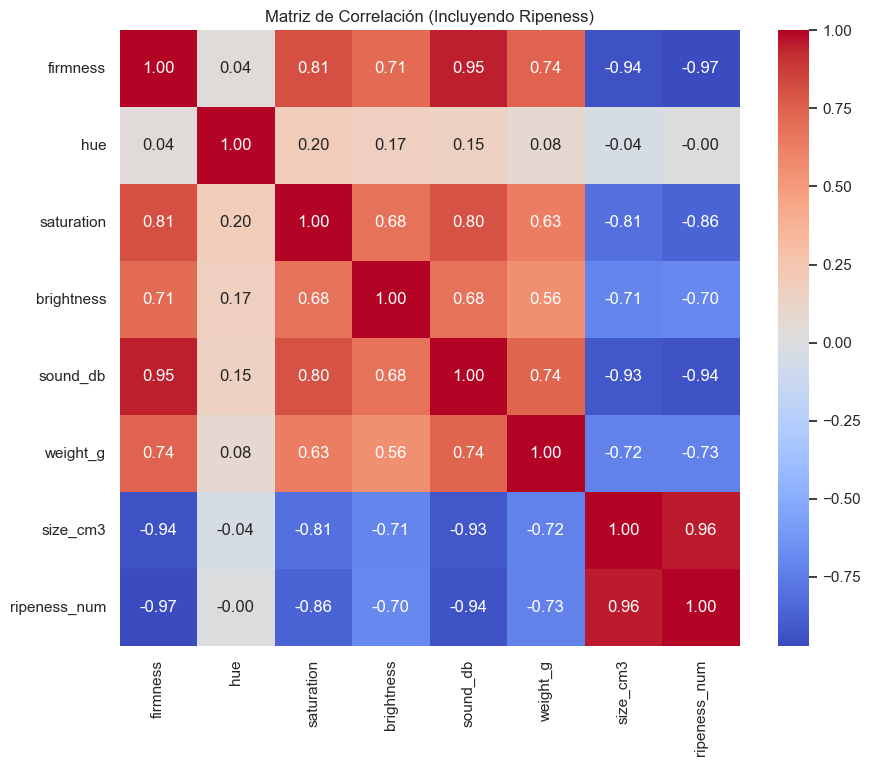

In [6]:
ripeness_map = {'hard': 0, 'pre-conditioned': 1, 'breaking': 2, 'ripe': 3}
df_corr = df.copy()
df_corr['ripeness_num'] = df_corr['ripeness'].map(ripeness_map)

plt.figure(figsize=(10, 8))
sns.heatmap(df_corr.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de Correlación (Incluyendo Ripeness)')
plt.show()

# Preprocesamiento y División del Dataset

primero hicimos el one-hot encoding para las variables categóricas, que en este caso era solamente el color. Esto nos agregó dos columnas más

In [7]:
numerical_features = ["firmness", "hue", "saturation", "brightness", "sound_db", "weight_g", "size_cm3"]
categorical_features = ["color_category"]

df_encoded = pd.get_dummies(df, columns=categorical_features, drop_first=True, dtype=int)
print(df_encoded.shape)
df_encoded.head()

(250, 11)


,firmness,hue,saturation,brightness,sound_db,weight_g,size_cm3,ripeness,color_category_dark green,color_category_green,color_category_purple
0,14.5,19,40,26,34,175,261,ripe,0,0,0
1,71.7,53,69,75,69,206,185,pre-conditioned,0,1,0
2,88.5,60,94,46,79,220,143,hard,1,0,0
3,93.8,105,87,41,75,299,140,hard,1,0,0
4,42.5,303,58,32,63,200,227,breaking,0,0,1


In [8]:
ripeness_mapping = {'hard': 0, 'pre-conditioned': 1, 'breaking': 2, 'ripe': 3, 'firm-ripe': 4}
y = df_encoded["ripeness"].map(ripeness_mapping)

X = df_encoded.drop(columns=["ripeness"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# Entrenamiento de modelos

## LDA

=== RESULTADOS LDA ===
Accuracy en Test: 1.0000

                 precision    recall  f1-score   support

           hard       1.00      1.00      1.00        15
pre-conditioned       1.00      1.00      1.00        15
       breaking       1.00      1.00      1.00        15
           ripe       1.00      1.00      1.00        15
      firm-ripe       1.00      1.00      1.00        15

       accuracy                           1.00        75
      macro avg       1.00      1.00      1.00        75
   weighted avg       1.00      1.00      1.00        75



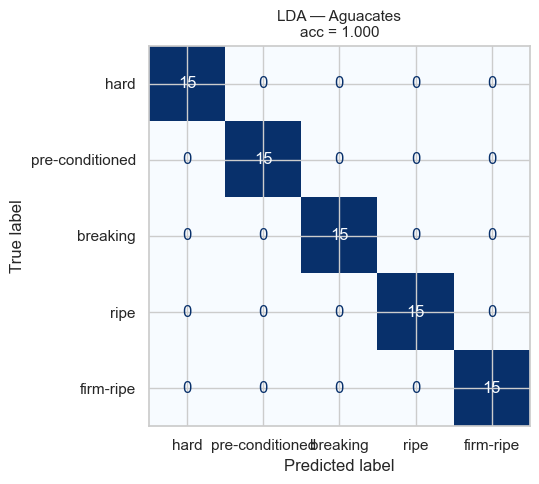

In [9]:
lda = LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto')
lda.fit(X_train_s, y_train)

y_pred_lda = lda.predict(X_test_s)
acc_lda = accuracy_score(y_test, y_pred_lda)

class_names = ['hard', 'pre-conditioned', 'breaking', 'ripe', 'firm-ripe']

print(f"=== RESULTADOS LDA ===")
print(f"Accuracy en Test: {acc_lda:.4f}\n")
print(classification_report(y_test, y_pred_lda, target_names=[class_names[i] for i in sorted(y_test.unique())]))

# Matriz de Confusión estilo Lab
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lda, 
    display_labels=[class_names[i] for i in sorted(y_test.unique())], 
    cmap="Blues", 
    values_format="d", 
    ax=ax, 
    colorbar=False
)
ax.set_title(f"LDA — Aguacates\nacc = {acc_lda:.3f}", fontsize=11)
plt.tight_layout()
plt.show()

## KNN

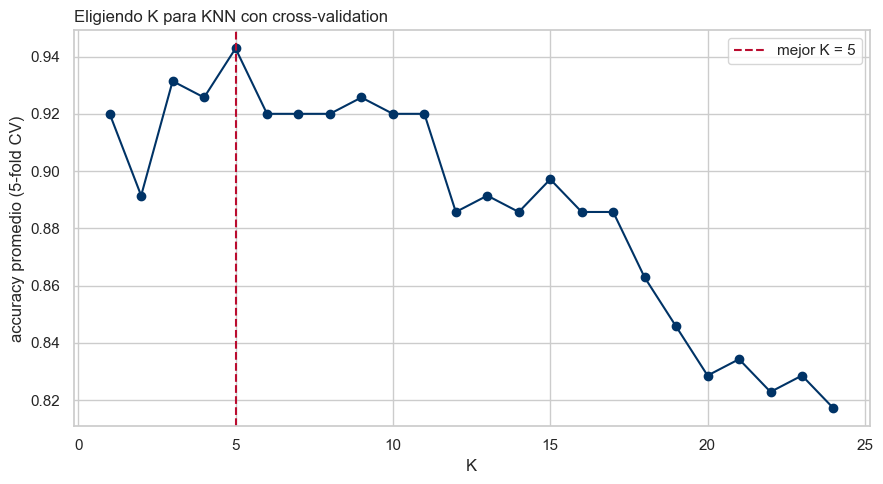

In [10]:
k_grid = range(1, 25)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in k_grid]
best_k = list(k_grid)[int(np.argmax(cv_scores))]

plt.figure(figsize=(9, 5))
plt.plot(list(k_grid), cv_scores, marker="o", color=UP_BLUE)
plt.axvline(best_k, color=UP_RED, ls="--", label=f"mejor K = {best_k}")
plt.xlabel("K")
plt.ylabel("accuracy promedio (5-fold CV)")
plt.title("Eligiendo K para KNN con cross-validation", loc="left")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
KNN_model = KNeighborsClassifier(n_neighbors=best_k)
KNN_model.fit(X_train, y_train)
y_pred_knn = KNN_model.predict(X_test)
acc_knn = accuracy_score(y_test, y_pred_knn)

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

baseline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    DummyClassifier(strategy="most_frequent")
)

scores = cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Baseline promedio:", scores.mean())
print("Desviación estándar:", scores.std())

Baseline promedio: 0.2
Desviación estándar: 0.0


=== RESULTADOS KNN SIN ESCALAR (K=5) ===
Accuracy en Test: 0.9467

Reporte de Clasificación:
                 precision    recall  f1-score   support

           hard       1.00      1.00      1.00        15
pre-conditioned       1.00      1.00      1.00        15
       breaking       1.00      0.87      0.93        15
           ripe       0.88      1.00      0.94        15
      firm-ripe       0.87      0.87      0.87        15

       accuracy                           0.95        75
      macro avg       0.95      0.95      0.95        75
   weighted avg       0.95      0.95      0.95        75



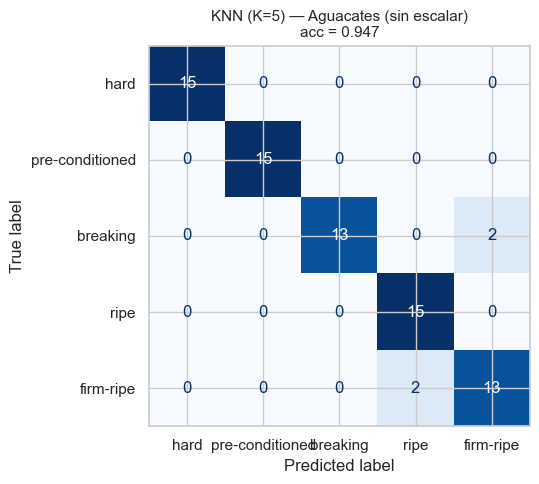

In [14]:
print(f"=== RESULTADOS KNN SIN ESCALAR (K={best_k}) ===")
print(f"Accuracy en Test: {acc_knn:.4f}\n")

# Filtramos class_names para mostrar únicamente las clases presentes en y_test
class_names = ['hard', 'pre-conditioned', 'breaking', 'ripe', 'firm-ripe']
target_names_test = [class_names[i] for i in sorted(y_test.unique())]

print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred_knn, target_names=target_names_test))

# 5. Matriz de Confusión estilo Lab
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_knn, 
    display_labels=target_names_test, 
    cmap="Blues", 
    values_format="d", 
    ax=ax, 
    colorbar=False
)
ax.set_title(f"KNN (K={best_k}) — Aguacates (sin escalar)\nacc = {acc_knn:.3f}", fontsize=11)
plt.tight_layout()
plt.show()

## Árbol de decisión

In [15]:
arbol_completo = DecisionTreeClassifier(random_state=42)
path = arbol_completo.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1]  # Excluimos el último alpha que dejaría un árbol de 1 solo nodo

# 2. Validación cruzada para encontrar el mejor alpha
cv_scores = []
for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    scores = cross_val_score(tree, X_train, y_train, cv=3, scoring="accuracy")
    cv_scores.append(scores.mean())

best_alpha = ccp_alphas[int(np.argmax(cv_scores))]
print(f"Mejor alpha por CV: {best_alpha:.4f}\n")

# 3. Entrenar el modelo final podado
model_dt_pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha)
model_dt_pruned.fit(X_train, y_train)

# 4. Predicción en el conjunto de prueba
y_pred_dt = model_dt_pruned.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)

# 5. Reporte de Clasificación con etiquetas descriptivas
class_names = ['hard', 'pre-conditioned', 'breaking', 'ripe', 'firm-ripe']
target_names_test = [class_names[i] for i in sorted(y_test.unique())]

print("=== RESULTADOS ÁRBOL DE DECISIÓN (PODADO) ===")
print(f"Accuracy en Test: {acc_dt:.4f}\n")
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred_dt, target_names=target_names_test, zero_division=0))

Mejor alpha por CV: 0.0000

=== RESULTADOS ÁRBOL DE DECISIÓN (PODADO) ===
Accuracy en Test: 1.0000

Reporte de Clasificación:
                 precision    recall  f1-score   support

           hard       1.00      1.00      1.00        15
pre-conditioned       1.00      1.00      1.00        15
       breaking       1.00      1.00      1.00        15
           ripe       1.00      1.00      1.00        15
      firm-ripe       1.00      1.00      1.00        15

       accuracy                           1.00        75
      macro avg       1.00      1.00      1.00        75
   weighted avg       1.00      1.00      1.00        75



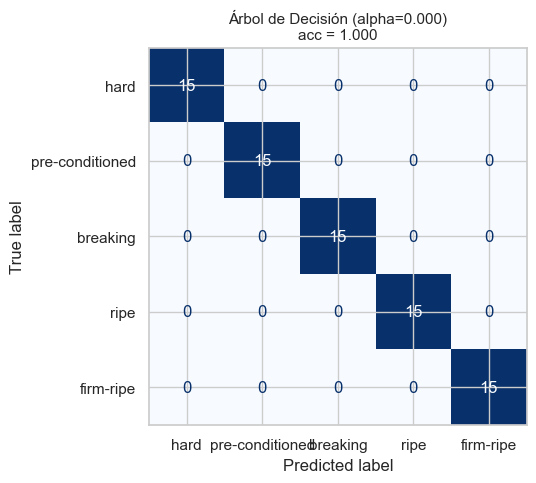

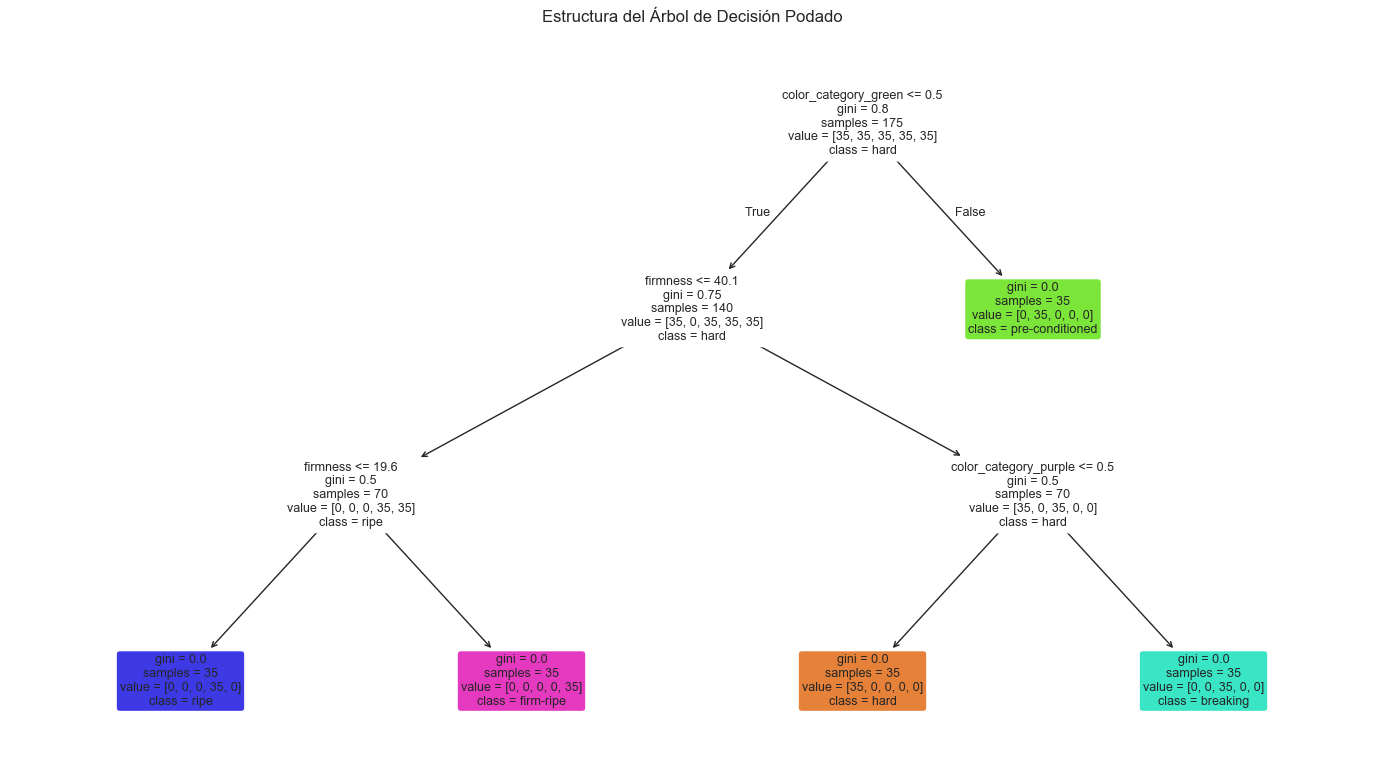

In [16]:
# 6. Visualización de la Matriz de Confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_dt, 
    display_labels=target_names_test, 
    cmap="Blues", 
    values_format="d", 
    ax=ax, 
    colorbar=False
)
ax.set_title(f"Árbol de Decisión (alpha={best_alpha:.3f})\nacc = {acc_dt:.3f}", fontsize=11)
plt.tight_layout()
plt.show()

# 7. Graficar la estructura del Árbol de Decisión Podado
plt.figure(figsize=(14, 8))
plot_tree(
    model_dt_pruned, 
    feature_names=X.columns, 
    class_names=target_names_test, 
    filled=True, 
    rounded=True, 
    fontsize=9
)
plt.title("Estructura del Árbol de Decisión Podado", fontsize=12)
plt.tight_layout()
plt.show()

## Random Forest

=== RESULTADOS RANDOM FOREST ===
Accuracy en Test: 1.0000

Reporte de Clasificación:
                 precision    recall  f1-score   support

           hard       1.00      1.00      1.00        15
pre-conditioned       1.00      1.00      1.00        15
       breaking       1.00      1.00      1.00        15
           ripe       1.00      1.00      1.00        15
      firm-ripe       1.00      1.00      1.00        15

       accuracy                           1.00        75
      macro avg       1.00      1.00      1.00        75
   weighted avg       1.00      1.00      1.00        75



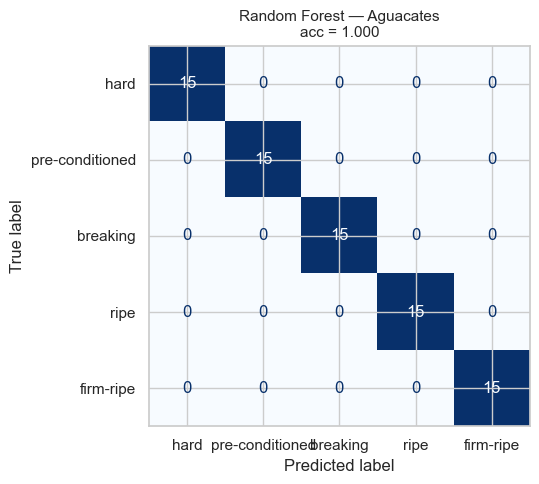

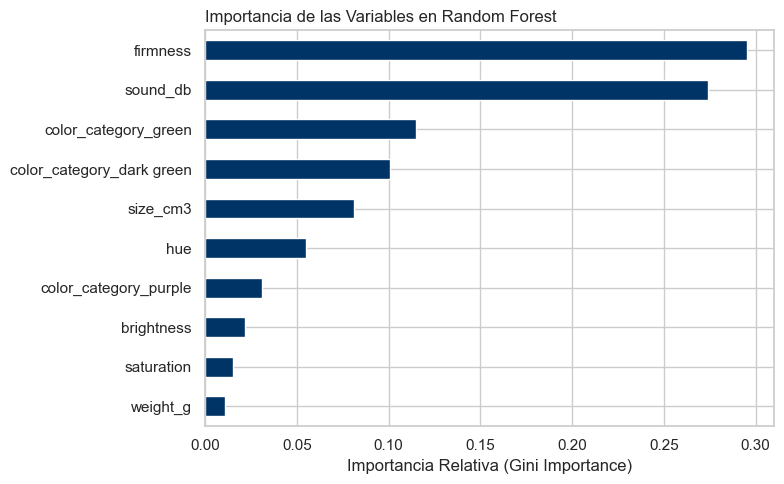

In [17]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 2. Predicción en el conjunto de prueba (X_test)
y_pred_rf = rf_model.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)

# 3. Reporte de Clasificación con etiquetas reales
class_names = ['hard', 'pre-conditioned', 'breaking', 'ripe', 'firm-ripe']
target_names_test = [class_names[i] for i in sorted(y_test.unique())]

print("=== RESULTADOS RANDOM FOREST ===")
print(f"Accuracy en Test: {acc_rf:.4f}\n")
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred_rf, target_names=target_names_test, zero_division=0))

# 4. Visualización de la Matriz de Confusión estilo Lab
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf, 
    display_labels=target_names_test, 
    cmap="Blues", 
    values_format="d", 
    ax=ax, 
    colorbar=False
)
ax.set_title(f"Random Forest — Aguacates\nacc = {acc_rf:.3f}", fontsize=11)
plt.tight_layout()
plt.show()

# 5. Gráfica de Importancia de Variables (Feature Importance)
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color=UP_BLUE)
plt.title("Importancia de las Variables en Random Forest", loc="left", fontsize=12)
plt.xlabel("Importancia Relativa (Gini Importance)")
plt.tight_layout()
plt.show()